# ANA500 Micro-Project 2
Charles Ayuk | November 7, 2026

Source: supplied airline.csv. Repository: [https://github.com/ChalesManyang/ANA500-Micro-Projects](https://github.com/ChalesManyang/ANA500-Micro-Projects)

Run cells in order. Python 3.11+ and requirements.txt are recommended.


## Acquire: load the supplied file and inspect its structure.

In [1]:
# Acquire: load the supplied file and inspect its structure.
from pathlib import Path
import numpy as np
import pandas as pd
# Keep airline.csv beside this notebook, or edit DATA_PATH below.
DATA_PATH = Path('airline.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../airline.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../../upload/airline.csv')
raw = pd.read_csv(DATA_PATH)
print('Raw rows and columns:', raw.shape)
print(raw.dtypes.to_string())
print('Missing values:', raw.isna().sum()[raw.isna().sum() > 0].to_dict())



Raw rows and columns: (129880, 25)
Unnamed: 0                             int64
id                                     int64
Gender                                object
Customer Type                         object
Age                                    int64
Type of Travel                        object
Class                                 object
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Inflight service                       int64
Cleanliness         

## Prepare: preserve raw data and create an independent working copy.

In [2]:
# Prepare: preserve raw data and create an independent working copy.
df = raw.copy()
for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip()
# The exported row counter is not a passenger attribute.
df = df.drop(columns=[c for c in df if c.startswith('Unnamed:')])
# Check complete duplicate records before considering any removal.
print('Exact duplicate rows:', int(df.duplicated().sum()))
print('Repeated passenger IDs:', int(df['id'].duplicated().sum()))
# Preserve valid zero ratings; their meaning is undocumented in this upload.
# Never assume zero means missing without a data dictionary.
ratings = list(df.loc[:, 'Inflight wifi service':'Cleanliness'].columns)
assert df[ratings].apply(lambda s: s.between(0, 5).all()).all()
assert df['Age'].between(0, 120).all()
assert (df[['Flight Distance', 'Departure Delay in Minutes']].to_numpy() >= 0).all()
print('Rating range:', int(df[ratings].min().min()), int(df[ratings].max().max()))
# Keep missing arrival delays as NaN. Project 4 excludes them as unknown targets.
print(df[['Age','Flight Distance','Departure Delay in Minutes',
          'Arrival Delay in Minutes']].describe().round(2).to_string())
print('Satisfied share (%):', round(df['satisfaction'].eq('satisfied').mean()*100, 2))
# NumPy arrays support explicit missing-value-aware numerical summaries.
arrivals = df['Arrival Delay in Minutes'].to_numpy(dtype=float)
print('Arrival mean / median:', np.nanmean(arrivals), np.nanmedian(arrivals))
print('Known arrival values:', int(np.isfinite(arrivals).sum()))
print('Preparation complete. No missing targets were filled.')



Exact duplicate rows: 0
Repeated passenger IDs: 0
Rating range: 0 5
             Age  Flight Distance  Departure Delay in Minutes  Arrival Delay in Minutes
count  129880.00        129880.00                   129880.00                 129487.00
mean       39.43          1190.32                       14.71                     15.09
std        15.12           997.45                       38.07                     38.47
min         7.00            31.00                        0.00                      0.00
25%        27.00           414.00                        0.00                      0.00
50%        40.00           844.00                        0.00                      0.00
75%        51.00          1744.00                       12.00                     13.00
max        85.00          4983.00                     1592.00                   1584.00
Satisfied share (%): 43.45
Arrival mean / median: 15.09112883918849 0.0
Known arrival values: 129487
Preparation complete. No missing target

## Analyze: summarize associations with satisfaction using Pandas.

In [3]:
# Analyze: summarize associations with satisfaction using Pandas.
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 140
# This binary indicator is only for descriptive summaries in Project 2.
df['satisfied'] = df['satisfaction'].eq('satisfied').astype(int)
class_rates = df.groupby('Class')['satisfied'].agg(['mean','size'])
print('Satisfaction by class:', class_rates.to_string())
correlations = df[ratings + ['satisfied']].corr()['satisfied'].drop('satisfied')
print('Rating associations (Pearson):', correlations.sort_values(ascending=False).round(3).to_string())



Satisfaction by class:               mean   size
Class                    
Business  0.694434  62160
Eco       0.187673  58309
Eco Plus  0.246414   9411
Rating associations (Pearson): Online boarding                      0.502
Inflight entertainment               0.398
Seat comfort                         0.349
On-board service                     0.322
Leg room service                     0.312
Cleanliness                          0.307
Inflight wifi service                0.283
Baggage handling                     0.249
Inflight service                     0.245
Checkin service                      0.237
Food and drink                       0.211
Ease of Online booking               0.169
Gate location                       -0.003
Departure/Arrival time convenient   -0.054


## Report: compare satisfaction across travel classes with a bar chart.

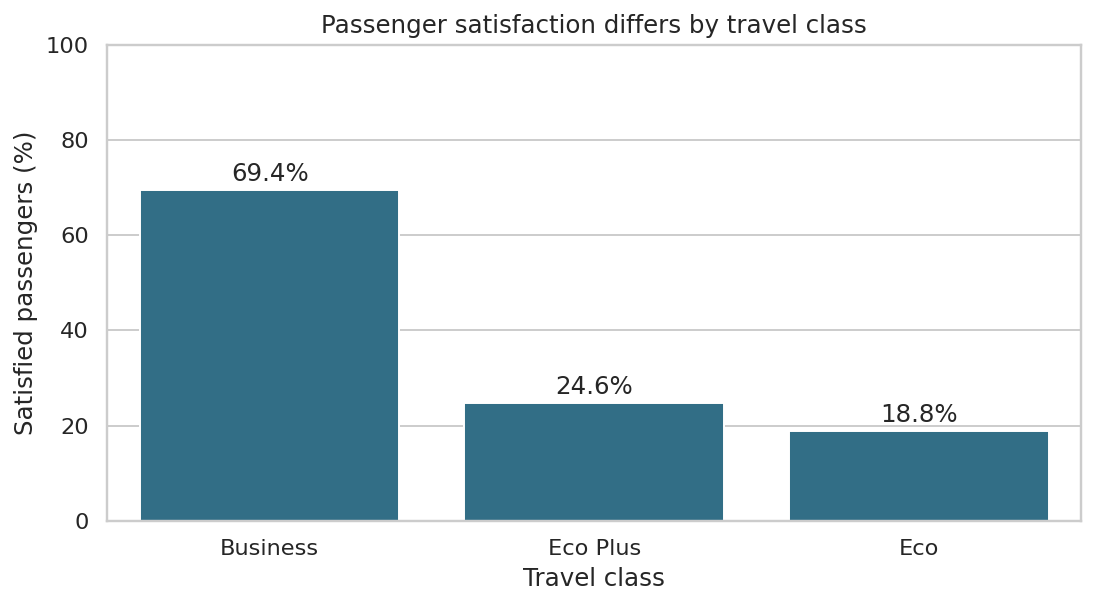

In [4]:
# Report: compare satisfaction across travel classes with a bar chart.
fig, ax = plt.subplots(figsize=(8,4.5))
rates = class_rates['mean'].sort_values(ascending=False)*100
sns.barplot(x=rates.index, y=rates.values, color='#247494', ax=ax)
ax.set(xlabel='Travel class', ylabel='Satisfied passengers (%)', ylim=(0,100),
       title='Passenger satisfaction differs by travel class')
for i,v in enumerate(rates): ax.text(i,v+2,f'{v:.1f}%',ha='center')
fig.tight_layout(); plt.show()



## Report: show service-rating associations without implying causation.

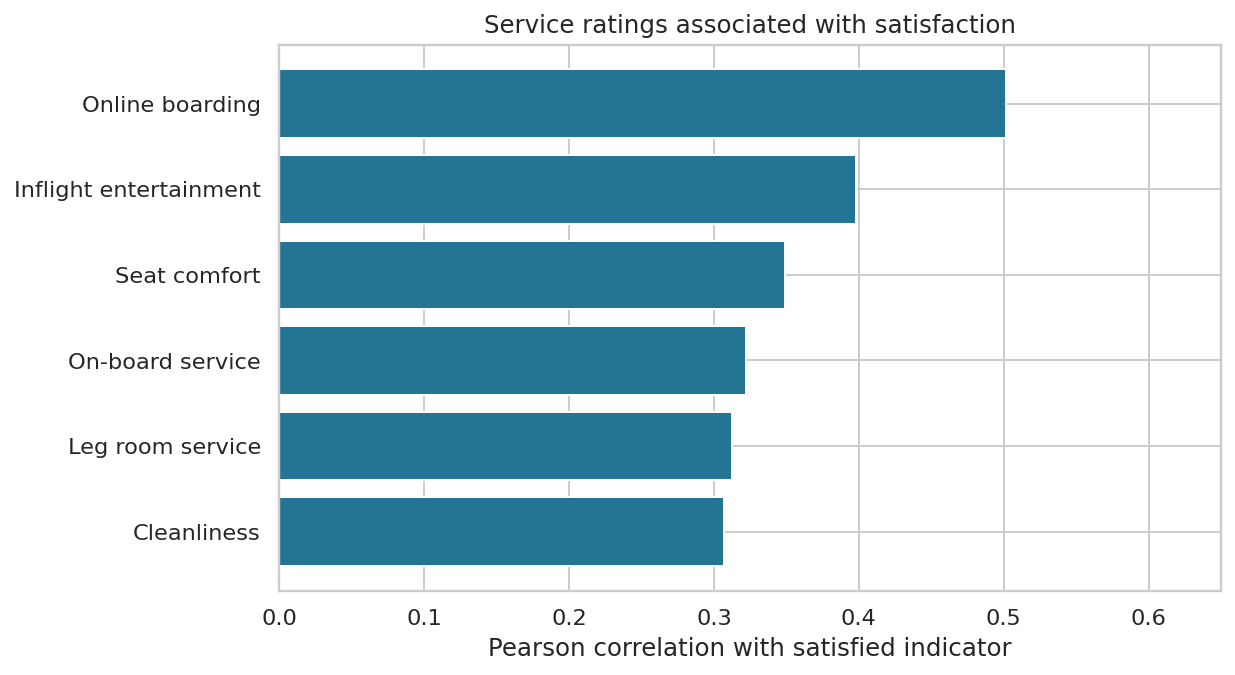

In [5]:
# Report: show service-rating associations without implying causation.
fig, ax = plt.subplots(figsize=(9,5))
top = correlations.sort_values().tail(6)
ax.barh(top.index,top.values,color='#247494')
ax.set(xlabel='Pearson correlation with satisfied indicator',xlim=(0,.65),
       title='Service ratings associated with satisfaction')
fig.tight_layout(); plt.show()



## Report: inspect delay distributions and the departure-arrival relationship.

Arrival delays above 240 minutes: 616
Departure-arrival correlation: 0.9652911835463153
Interpretation: associations identify questions for investigation; they do not establish causes.
Limitations: observational survey, unknown sampling method and no dates or airline IDs.
Project 2 ends at Report. No intervention or causal claim is made.


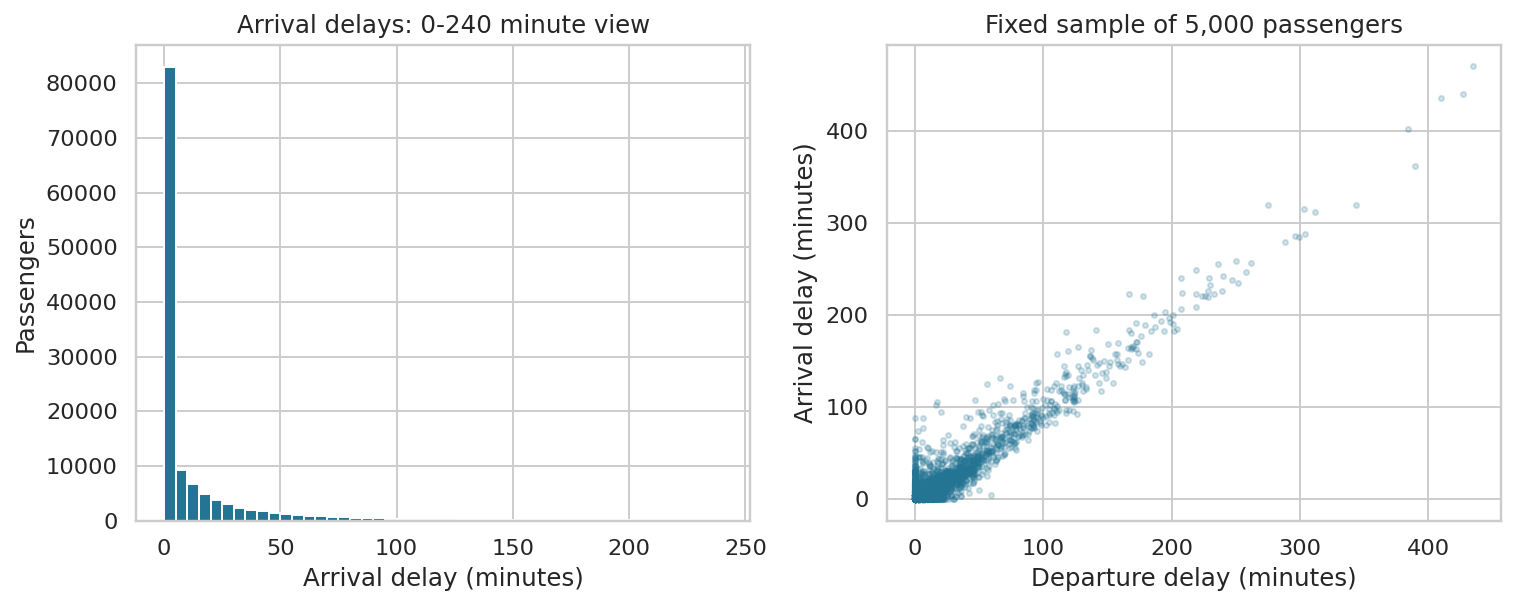

In [6]:
# Report: inspect delay distributions and the departure-arrival relationship.
# Sample only for plotting, using a fixed seed; statistics use all known values.
known = df.dropna(subset=['Arrival Delay in Minutes'])
fig, axes = plt.subplots(1,2,figsize=(11,4.5))
axes[0].hist(known['Arrival Delay in Minutes'],bins=np.arange(0,245,5),color='#247494')
axes[0].set(xlabel='Arrival delay (minutes)',ylabel='Passengers',
            title='Arrival delays: 0-240 minute view')
subset=known.sample(n=min(5000,len(known)),random_state=42)
axes[1].scatter(subset['Departure Delay in Minutes'],subset['Arrival Delay in Minutes'],
                s=7,alpha=.2,color='#247494')
axes[1].set(xlabel='Departure delay (minutes)',ylabel='Arrival delay (minutes)',
            title='Fixed sample of 5,000 passengers')
fig.tight_layout(); plt.show()
print('Arrival delays above 240 minutes:', int((known['Arrival Delay in Minutes']>240).sum()))
print('Departure-arrival correlation:', known[['Departure Delay in Minutes','Arrival Delay in Minutes']].corr().iloc[0,1])
print('Interpretation: associations identify questions for investigation; they do not establish causes.')
print('Limitations: observational survey, unknown sampling method and no dates or airline IDs.')
print('Project 2 ends at Report. No intervention or causal claim is made.')
